# 1. A first look at maximum likelihood  [MLE 1.1–1.3.5]

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown, fixed

np.set_printoptions(precision=4, suppress=True)
from scipy.stats import binom, norm
from scipy.special import xlogy
from scipy.optimize import minimize_scalar

def check(label, ok):
    print(f"{'✓' if ok else '✗'}  {label}")

---
## 1.1 Five coins

**Task.** Reproduce the example in [MLE 1.3.2]: five coins with $\theta_i = i/4$, $i = 0,\dots,4$, and observation $y = (1, 0, 0)$. Compute $p(y\mid\theta_i)$ for each coin, plot it as a bar chart and mark $\hat\theta_{ML}$. Then fix the true value $\theta = 1/2$, simulate 10,000 experimenters with $m = 3$ tosses each, and plot the histogram of their estimates $\hat\theta_{ML}$.

### Prediction

- $p(y\mid\theta) = \theta(1-\theta)^2$: $0,\ 9/64,\ 8/64,\ 3/64,\ 0$, so $\hat\theta_{ML} = 1/4$.
- With $m = 3$ the observed head fraction $k/3$ is $0, 1/3, 2/3$ or $1$. Each is mapped to the closest coin *in likelihood*, and $1/3 \mapsto 1/4$, $2/3 \mapsto 3/4$, so the histogram has bars at $0, 1/4, 3/4, 1$ and **none at $1/2$**.

p(y | θ_i) = [0.     0.1406 0.125  0.0469 0.    ]  (×64: [0. 9. 8. 3. 0.] )
θ_ML = 0.25


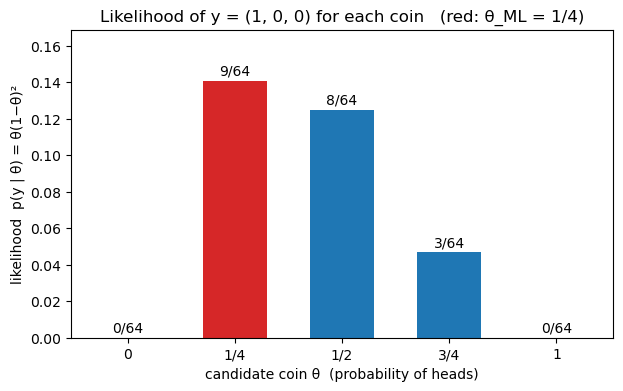

In [22]:
thetas = np.arange(5) / 4                      # the five candidate coins
y = np.array([1, 0, 0])

def likelihood(y, theta):
    k, m = y.sum(), y.size
    return theta**k * (1 - theta)**(m - k)

lik = likelihood(y, thetas)
theta_ml = thetas[np.argmax(lik)]
print("p(y | θ_i) =", lik, " (×64:", lik * 64, ")")
print("θ_ML =", theta_ml)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(thetas, lik, width=0.15, color=["C0" if t != theta_ml else "C3" for t in thetas])
ax.bar_label(bars, labels=[f"{round(v * 64)}/64" for v in lik], padding=2)
ax.set_xticks(thetas, labels=["0", "1/4", "1/2", "3/4", "1"])
ax.set_xlabel("candidate coin θ  (probability of heads)")
ax.set_ylabel("likelihood  p(y | θ) = θ(1−θ)²")
ax.set_ylim(0, lik.max() * 1.2)
ax.set_title(f"Likelihood of y = {tuple(int(v) for v in y)} for each coin   (red: θ_ML = 1/4)")
plt.show()

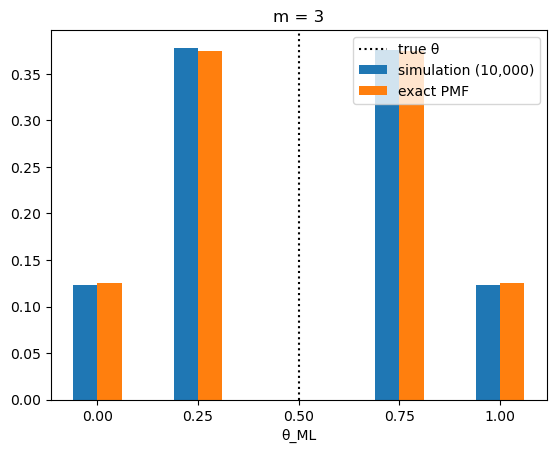

simulated: [0.123  0.3783 0.     0.3757 0.123 ] 
exact    : [0.125 0.375 0.    0.375 0.125]


In [23]:
def ml_on_grid(k, m, grid=thetas):
    # ML estimate restricted to the candidate coins, for every k in an array (ties -> smallest θ)
    k = np.atleast_1d(k)[:, None]
    with np.errstate(divide="ignore"):
        loglik = xlogy(k, grid) + xlogy(m - k, 1 - grid)          # xlogy uses 0·log 0 = 0
    return grid[np.argmax(loglik, axis=1)]

def exact_pmf(m, theta_true, grid=thetas):
    # P(θ_ML = θ_i): add up the binomial probabilities of every k that maps to θ_i
    ks = np.arange(m + 1)
    est = ml_on_grid(ks, m, grid)
    return np.array([binom.pmf(ks[est == g], m, theta_true).sum() for g in grid])

def simulate_experimenters(m, theta_true=0.5, n_exp=10_000, seed=0):
    rng = np.random.default_rng(seed)
    tosses = rng.random((n_exp, m)) < theta_true    # each row: one experimenter
    return ml_on_grid(tosses.sum(axis=1), m)

def plot_estimates(m, theta_true=0.5, ax=None):
    est = simulate_experimenters(m, theta_true)
    freq = np.array([np.mean(est == g) for g in thetas])
    pmf = exact_pmf(m, theta_true)
    ax = ax or plt.gca()
    ax.bar(thetas - 0.03, freq, width=0.06, label="simulation (10,000)")
    ax.bar(thetas + 0.03, pmf, width=0.06, label="exact PMF")
    ax.axvline(theta_true, color="k", ls=":", label="true θ")
    ax.set_xticks(thetas); ax.set_title(f"m = {m}"); ax.set_xlabel("θ_ML")
    return freq, pmf

freq, pmf = plot_estimates(3); plt.legend(); plt.show()
print("simulated:", freq, "\nexact    :", pmf)

### Verify numerically

In [24]:
check("p(y|θ) = (0, 9/64, 8/64, 3/64, 0)  [MLE 1.3.2]", np.allclose(lik, np.array([0, 9, 8, 3, 0]) / 64))
check("θ_ML = 1/4", theta_ml == 0.25)
check("exact PMF for m = 3 is (1/8, 3/8, 0, 3/8, 1/8)  [MLE 1.3.3]", np.allclose(pmf, [1/8, 3/8, 0, 3/8, 1/8]))
check("simulated frequencies within 0.015 of the exact PMF", np.allclose(freq, pmf, atol=0.015))
check("no experimenter ever gets θ_ML = 1/2 with m = 3", freq[2] == 0)

✓  p(y|θ) = (0, 9/64, 8/64, 3/64, 0)  [MLE 1.3.2]
✓  θ_ML = 1/4
✓  exact PMF for m = 3 is (1/8, 3/8, 0, 3/8, 1/8)  [MLE 1.3.3]
✓  simulated frequencies within 0.015 of the exact PMF
✓  no experimenter ever gets θ_ML = 1/2 with m = 3


### Explore: m = 10, 30, 100 tosses (same five candidate coins)

m =   3:  P(θ_ML = 1/2) = 0.0000   (simulated 0.0000)
m =  10:  P(θ_ML = 1/2) = 0.6563   (simulated 0.6552)
m =  30:  P(θ_ML = 1/2) = 0.7995   (simulated 0.7975)
m = 100:  P(θ_ML = 1/2) = 0.9934   (simulated 0.9944)


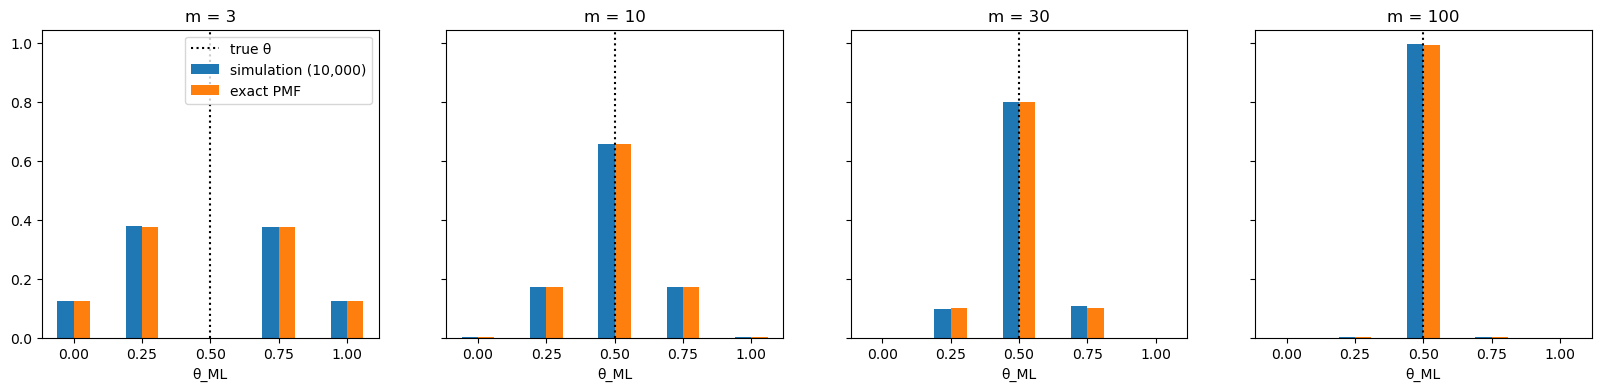

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, m in zip(axes, [3, 10, 30, 100]):
    freq, pmf = plot_estimates(m, ax=ax)
    print(f"m = {m:>3}:  P(θ_ML = 1/2) = {pmf[2]:.4f}   (simulated {freq[2]:.4f})")
axes[0].legend()
plt.show()

---
### Explain

**1. Compare the histogram with the exact PMF of $\hat\theta_{ML}$ in [MLE 1.3.3].**

The simulated frequencies match the exact PMF $(1/8, 3/8, 0, 3/8, 1/8)$ to within about 0.01, which is the Monte-Carlo error with 10,000 experimenters. The exact PMF comes from $k \sim \mathrm{Bin}(3, 1/2)$: $k=0 \to \hat\theta = 0$ (1/8), $k = 1 \to 1/4$ (3/8), $k = 2 \to 3/4$ (3/8), $k = 3 \to 1$ (1/8). As $m$ grows, the mass concentrates on $\theta = 1/2$: $P(\hat\theta_{ML} = 1/2)$ is 0.66 for $m = 10$, 0.80 for $m = 30$ and 0.993 for $m = 100$ (exact values, matched by the simulation). The coin $1/2$ wins whenever $k/m$ falls in its "basin" $(0.369, 0.631)$ (the midpoints in log-likelihood between the neighbouring coins), and $k/m$ concentrates around $1/2$ with standard deviation $0.5/\sqrt m$, so that probability tends to 1.

**2. Why does the ML estimator *never* return the true value 1/2 when $m = 3$?**

With three tosses $k/m \in \{0, 1/3, 2/3, 1\}$. For $k = 1$ the likelihoods are $9/64$ at $\theta = 1/4$ and $8/64$ at $\theta = 1/2$; the coin $1/4$ is closer to the observed frequency $1/3$, so it wins. By symmetry $k = 2$ picks $3/4$. No possible data set has $1/2$ as its most likely coin, so $P(\hat\theta_{ML} = 1/2) = 0$, even though $1/2$ is the truth. The estimator is restricted to a coarse grid and the data are too few to land in the middle cell.

**3. Why is $\hat\theta_{ML}$ a random variable?**

$\hat\theta_{ML} = T(y)$ is a deterministic function of the data, but the data $y$ are random (each experimenter tosses different outcomes). A function of a random vector is a random variable, so for a fixed true $\theta$ it has a distribution, the PMF plotted above. Its mean, variance and bias are properties of that distribution [MLE 1.3.3, 1.3.5].

---
## 1.2 The Bernoulli likelihood

**Task.** For the sequence $y = (1,0,0,1,0,0,0,1,0,0)$ of [MLE 1.1], plot on $\theta\in(0,1)$ both

$$p(y\mid\theta) = \theta^k(1-\theta)^{m-k}, \qquad \log p(y\mid\theta) = k\log\theta + (m-k)\log(1-\theta), \qquad k = \textstyle\sum_i y_i,$$

and mark the maximiser. Check numerically (`scipy.optimize.minimize_scalar`) that $\hat\theta_{ML} = k/m$.

### Prediction

- $k = 3$, $m = 10$, so both curves peak at $\theta = 0.3$; the likelihood is tiny (about $2\cdot10^{-3}$) and the log-likelihood is a concave bowl turned upside down.
- With $k/m = 0.3$ fixed, $\frac1m\log p$ is **the same curve** for every $m$: it only depends on $k/m$.

k = 3, m = 10:  minimize_scalar -> θ = 0.300000,   k/m = 0.3


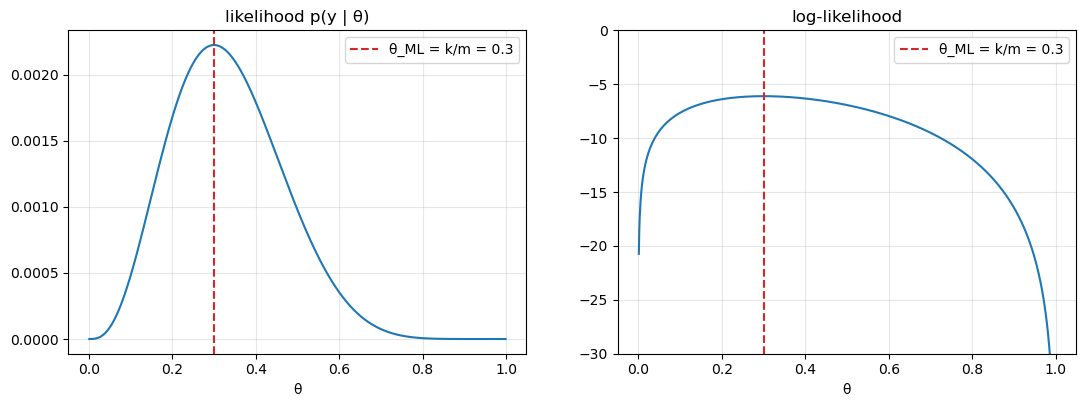

In [26]:
y = np.array([1, 0, 0, 1, 0, 0, 0, 1, 0, 0])
k, m = y.sum(), y.size
th = np.linspace(1e-3, 1 - 1e-3, 999)

def loglik(theta, k, m):
    return k * np.log(theta) + (m - k) * np.log(1 - theta)

res = minimize_scalar(lambda t: -loglik(t, k, m), bounds=(1e-9, 1 - 1e-9), method="bounded")
print(f"k = {k}, m = {m}:  minimize_scalar -> θ = {res.x:.6f},   k/m = {k/m}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ax1.plot(th, np.exp(loglik(th, k, m))); ax1.set_title("likelihood p(y | θ)")
ax2.plot(th, loglik(th, k, m)); ax2.set_title("log-likelihood"); ax2.set_ylim(-30, 0)
for ax in (ax1, ax2):
    ax.axvline(k / m, color="C3", ls="--", label=f"θ_ML = k/m = {k/m}")
    ax.set_xlabel("θ"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

### Verify numerically

In [27]:
dloglik = k / res.x - (m - k) / (1 - res.x)
d2 = -k / th**2 - (m - k) / (1 - th)**2
check("minimize_scalar gives θ_ML = k/m = 0.3", np.isclose(res.x, k / m, atol=1e-5))
check("d/dθ log p = k/θ − (m−k)/(1−θ) = 0 at θ_ML", np.isclose(dloglik, 0, atol=1e-3))
check("argmax of p equals argmax of log p on the grid", np.argmax(np.exp(loglik(th, k, m))) == np.argmax(loglik(th, k, m)))
check("d²/dθ² log p < 0 on the whole interval (concave)", np.all(d2 < 0))

✓  minimize_scalar gives θ_ML = k/m = 0.3
✓  d/dθ log p = k/θ − (m−k)/(1−θ) = 0 at θ_ML
✓  argmax of p equals argmax of log p on the grid
✓  d²/dθ² log p < 0 on the whole interval (concave)


### Explore: $k/m = 0.3$ with $m = 10, 100, 1000$

m =   10:  max likelihood p(y|θ_ML) = 2.224e-03
m =  100:  max likelihood p(y|θ_ML) = 2.955e-27
m = 1000:  max likelihood p(y|θ_ML) = 5.070e-266


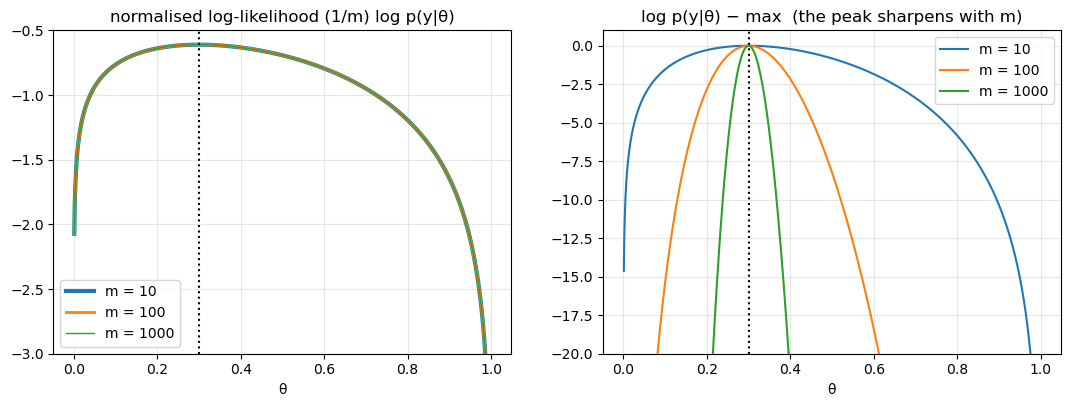


m = 2000: likelihood computed directly = 0.0   (underflows to 0)
m = 2000: log-likelihood = -1221.73   (perfectly representable)


In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for m_ in [10, 100, 1000]:
    k_ = int(0.3 * m_)
    ll = loglik(th, k_, m_)
    ax1.plot(th, ll / m_, label=f"m = {m_}", lw=4 - np.log10(m_))
    ax2.plot(th, ll - ll.max(), label=f"m = {m_}")
    print(f"m = {m_:>4}:  max likelihood p(y|θ_ML) = {np.exp(loglik(0.3, k_, m_)):.3e}")
ax1.set_title("normalised log-likelihood (1/m) log p(y|θ)"); ax1.set_ylim(-3, -0.5)
ax2.set_title("log p(y|θ) − max  (the peak sharpens with m)"); ax2.set_ylim(-20, 1)
for ax in (ax1, ax2):
    ax.axvline(0.3, color="k", ls=":"); ax.set_xlabel("θ"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

m_big = 2000
print(f"\nm = {m_big}: likelihood computed directly = {0.3**600 * 0.7**1400}   (underflows to 0)")
print(f"m = {m_big}: log-likelihood = {loglik(0.3, 600, m_big):.2f}   (perfectly representable)")

---
### Explain

**1. Why does maximising the log-likelihood give the same $\hat\theta$ as maximising the likelihood?**

$\log$ is strictly increasing, so $p(y\mid\theta_1) > p(y\mid\theta_2) \iff \log p(y\mid\theta_1) > \log p(y\mid\theta_2)$. The ordering of all $\theta$ values is preserved, so the argmax is the same (the grid check above confirms it). Only the *value* at the maximum changes, not its location.

**2. Why does the likelihood itself become numerically useless for large $m$, but not its logarithm?**

The likelihood is a product of $m$ numbers smaller than 1, so it decays exponentially: about $e^{-0.61 m}$ at $\theta = 0.3$. For $m = 1000$ it is about $10^{-265}$, and for $m = 2000$ it is below the smallest double ($\approx 10^{-308}$) and underflows to exactly 0, so every $\theta$ looks equally likely. The log turns the product into a sum, $k\log\theta + (m-k)\log(1-\theta)$, which grows only linearly in $m$ (about $-1222$ for $m = 2000$) and is perfectly representable. That is why software always works with log-likelihoods.

**3. Is $\log p(y\mid\theta)$ concave in $\theta$? (Link to Section 4.)**

Yes. $\frac{d^2}{d\theta^2}\log p = -\frac{k}{\theta^2} - \frac{m-k}{(1-\theta)^2} < 0$ on $(0,1)$, which the check above confirms on the whole grid. In Section 4 terms: $\log\theta$ and $\log(1-\theta)$ are concave (the second is a concave function of an affine map), and a non-negative weighted sum of concave functions is concave [CO 9.1–9.2]. So maximum likelihood here is a concave maximisation, equivalently a convex minimisation of $-\log p$: one maximum, found by setting the derivative to zero. The normalised curves for $m = 10, 100, 1000$ coincide exactly because $\frac1m\log p = \frac km\log\theta + (1-\frac km)\log(1-\theta)$ depends only on $k/m$; what changes with $m$ is the unnormalised curvature $m\cdot(\ldots)$, i.e. how sharply the data pin $\theta$ down.

---
## 1.3 Bias and variance of $\hat\theta_{ML}$

**Task.** For several true values $\theta \in \{0.1, 0.3, 0.5\}$ and $m \in \{5, 20, 100\}$, simulate many data sets and estimate $E(\hat\theta_{ML})$ and $\mathrm{Var}(\hat\theta_{ML})$. Overlay the histogram of $\hat\theta_{ML}$ with the binomial PMF of [MLE 1.3.5].

$$E(\hat\theta_{ML}) = \theta, \qquad \mathrm{Var}(\hat\theta_{ML}) = \frac{\theta(1-\theta)}{m}.$$

### Prediction

- The mean is always $\theta$ (unbiased); the variance is largest at $\theta = 0.5$ (where $\theta(1-\theta)$ peaks) and shrinks like $1/m$.
- For $\theta = 0.1$, $m = 5$ the histogram is very skewed (most data sets have $k = 0$); the Gaussian shape needs $m\theta(1-\theta)$ to be reasonably large (rule of thumb $\gtrsim 5$–10).

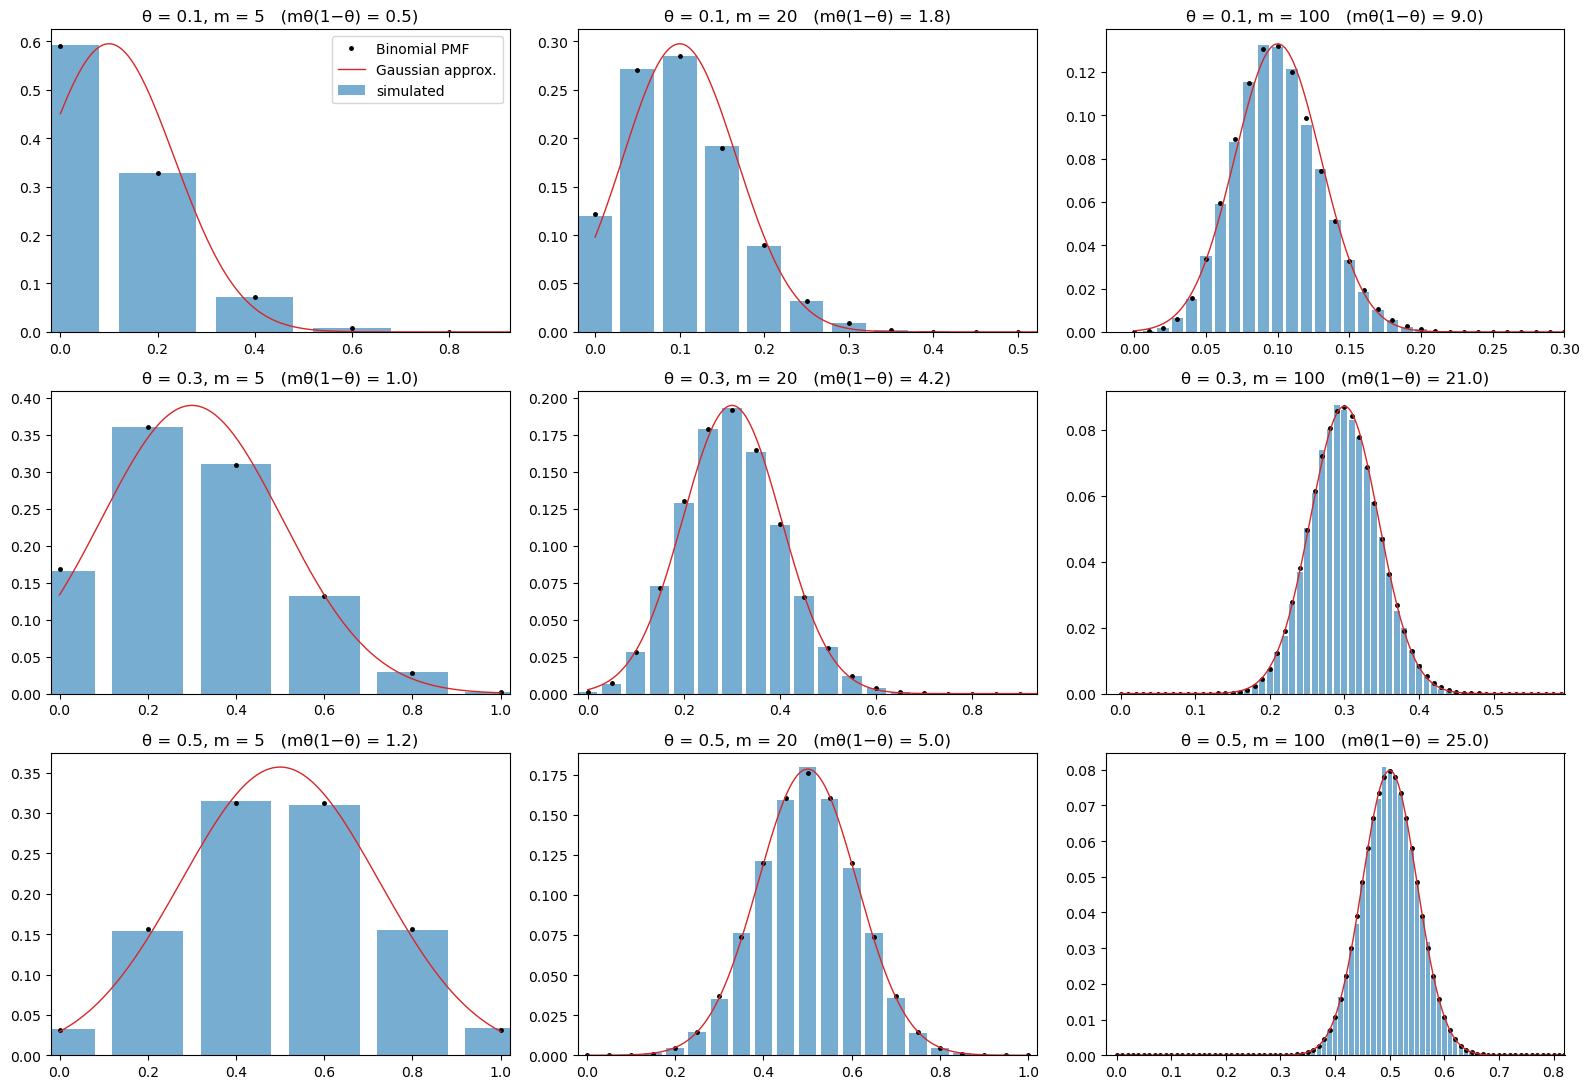

 θ     m  |  mean(sim)  θ      |  var(sim)    θ(1−θ)/m
0.1     5  |  0.0998   0.1000  |  0.017981   0.018000
0.1    20  |  0.1002   0.1000  |  0.004512   0.004500
0.1   100  |  0.0999   0.1000  |  0.000899   0.000900
0.3     5  |  0.3014   0.3000  |  0.042150   0.042000
0.3    20  |  0.3001   0.3000  |  0.010533   0.010500
0.3   100  |  0.3001   0.3000  |  0.002094   0.002100
0.5     5  |  0.5005   0.5000  |  0.050486   0.050000
0.5    20  |  0.4997   0.5000  |  0.012397   0.012500
0.5   100  |  0.5002   0.5000  |  0.002486   0.002500


In [29]:
n_sets = 50_000
rng = np.random.default_rng(1)
th_list, m_list = [0.1, 0.3, 0.5], [5, 20, 100]
table = []
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for i, theta in enumerate(th_list):
    for j, m in enumerate(m_list):
        est = (rng.random((n_sets, m)) < theta).sum(axis=1) / m     # θ_ML = k/m for each data set
        table.append((theta, m, est.mean(), theta, est.var(), theta * (1 - theta) / m))
        ax = axes[i, j]
        ks = np.arange(m + 1)
        freq = np.bincount((est * m).round().astype(int), minlength=m + 1) / n_sets
        ax.bar(ks / m, freq, width=0.8 / m, alpha=0.6, label="simulated")
        ax.plot(ks / m, binom.pmf(ks, m, theta), "k.", ms=5, label="Binomial PMF")
        sd = np.sqrt(theta * (1 - theta) / m)
        xx = np.linspace(0, 1, 400)
        ax.plot(xx, norm.pdf(xx, theta, sd) / m, "C3", lw=1, label="Gaussian approx.")
        ax.set_xlim(-0.02, min(1, theta + 6 * sd) + 0.02)
        ax.set_title(f"θ = {theta}, m = {m}   (mθ(1−θ) = {m * theta * (1 - theta):.1f})")
axes[0, 0].legend()
plt.tight_layout(); plt.show()

print(" θ     m  |  mean(sim)  θ      |  var(sim)    θ(1−θ)/m")
for theta, m, mean_s, mean_t, var_s, var_t in table:
    print(f"{theta:.1f}  {m:>4}  |  {mean_s:.4f}   {mean_t:.4f}  |  {var_s:.6f}   {var_t:.6f}")

### Verify numerically

In [30]:
tab = np.array(table)
check("E(θ_ML) = θ in every case (within Monte-Carlo error)", np.allclose(tab[:, 2], tab[:, 3], atol=0.003))
check("Var(θ_ML) = θ(1−θ)/m in every case (within 3%)", np.allclose(tab[:, 4], tab[:, 5], rtol=0.03))
check("for each m the variance is largest at θ = 0.5", all(
      tab[(tab[:, 1] == m), 4].argmax() == 2 for m in m_list))

✓  E(θ_ML) = θ in every case (within Monte-Carlo error)
✓  Var(θ_ML) = θ(1−θ)/m in every case (within 3%)
✓  for each m the variance is largest at θ = 0.5


---
### Explain

**1. For which $\theta$ is the estimator least precise, and why?**

At $\theta = 0.5$. $\mathrm{Var}(\hat\theta_{ML}) = \theta(1-\theta)/m$ and $\theta(1-\theta)$ is maximal (1/4) at $\theta = 1/2$; the simulation shows the same ordering for every $m$. A coin with $\theta$ near 0 or 1 gives almost always the same outcome, so each toss varies little; a fair coin is the most unpredictable, so the head *count* fluctuates most. (In *relative* terms, $\mathrm{sd}/\theta$, small $\theta$ is actually the hardest: for $\theta = 0.1, m = 5$ the relative error is about 134%.)

**2. From what $m$ on does the histogram look Gaussian [MLE 1.3.10]?**

It depends on $\theta$, through $m\theta(1-\theta)$ (the variance of the head count). For $\theta = 0.5$ the histogram is already bell-shaped at $m = 20$ ($m\theta(1-\theta) = 5$), and at $m = 100$ it is indistinguishable from the red Gaussian curve. For $\theta = 0.1$ it is still visibly skewed at $m = 20$ (it piles up against 0, $m\theta(1-\theta) = 1.8$) and only looks Gaussian at $m = 100$ ($= 9$). A practical rule is $m\theta(1-\theta) \gtrsim 5$–10. This is the asymptotic normality of ML estimators: $\hat\theta_{ML} \approx \mathcal N(\theta, 1/(m I(\theta)))$ with Fisher information $I(\theta) = 1/(\theta(1-\theta))$ per toss.